         NFCSID   A1   A2   A3  B2_1  B2_2  B2_3  B2_4  B2_5  B2_7  ...   G11  \
0  2.024010e+09  1.0  1.0  1.0   2.0   2.0   1.0   2.0   2.0   1.0  ...   1.0   
1  2.024010e+09  1.0  1.0  1.0   1.0   2.0   1.0   2.0   2.0   2.0  ...  98.0   
2  2.024010e+09  1.0  2.0  1.0   1.0   2.0   2.0   2.0   2.0   2.0  ...   2.0   
3  2.024010e+09  1.0  1.0  1.0   1.0   2.0   2.0   2.0   2.0   2.0  ...   1.0   
4  2.024010e+09  1.0  1.0  1.0   1.0   2.0   1.0   2.0   2.0   2.0  ...   3.0   

   G12  G13   G23      WGT1  S_Gender2  S_Age  S_Ethnicity  S_Education  \
0  3.0  4.0   3.0  0.615651        2.0    3.0          1.0          2.0   
1  2.0  3.0  98.0  0.615651        2.0    3.0          2.0          2.0   
2  1.0  2.0   1.0  0.885309        2.0    2.0          1.0          2.0   
3  3.0  4.0   1.0  0.615651        1.0    3.0          1.0          2.0   
4  3.0  4.0  98.0  0.615651        1.0    3.0          1.0          2.0   

   S_Income  
0       2.0  
1       1.0  
2       1.0  
3     

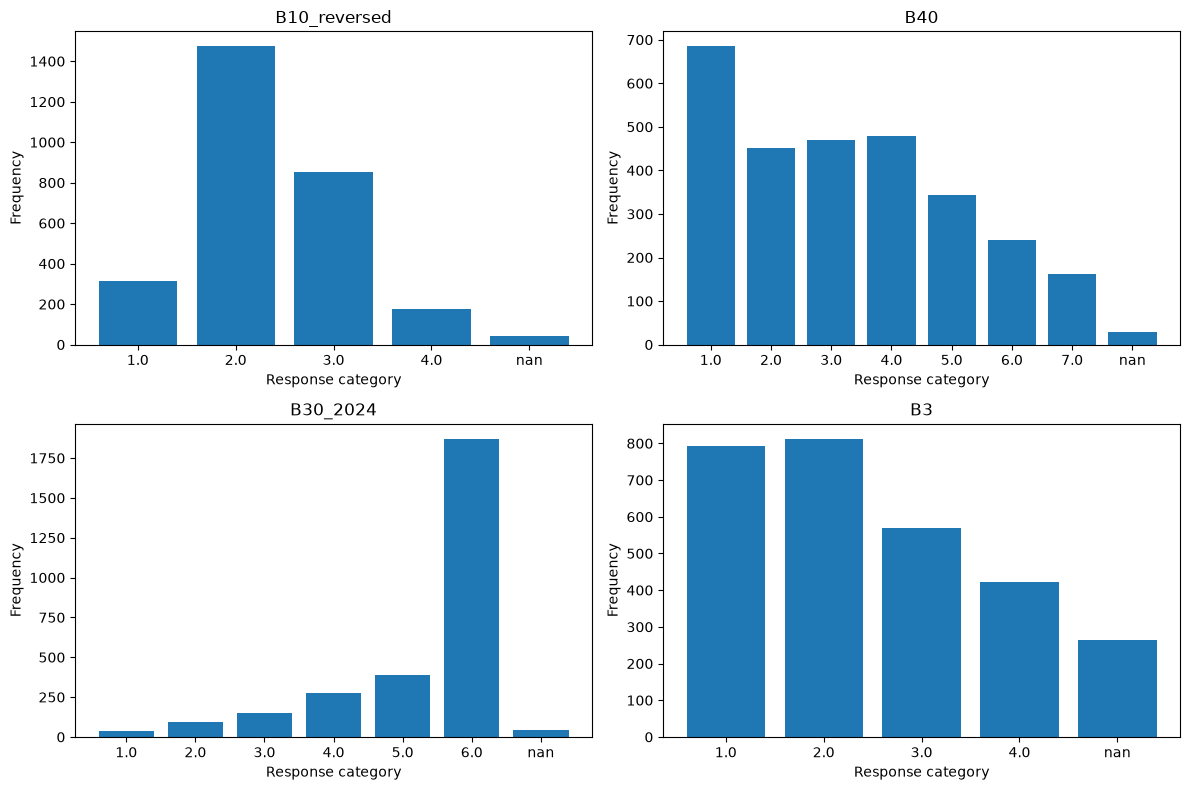

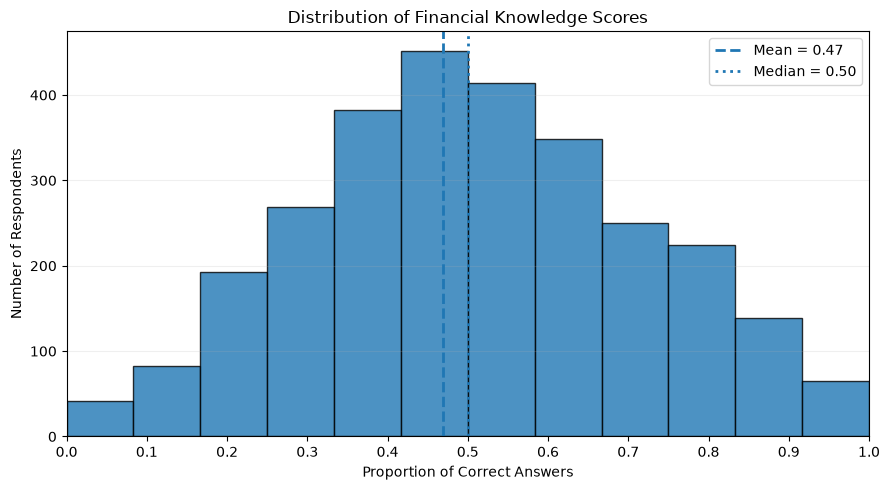


SPEARMAN CORRELATIONS
                  B10_reversed    B40  B30_2024     B3  knowledge_score
B10_reversed            1.000  0.505    -0.134  0.309            0.171
B40                     0.505  1.000    -0.311  0.204           -0.056
B30_2024               -0.134 -0.311     1.000 -0.062            0.236
B3                      0.309  0.204    -0.062  1.000            0.264
knowledge_score         0.171 -0.056     0.236  0.264            1.000

CORRELATION SAMPLE SIZES
                  B10_reversed   B40  B30_2024    B3  knowledge_score
B10_reversed             2816  2792      2780  2564             2816
B40                      2792  2831      2792  2570             2831
B30_2024                 2780  2792      2818  2565             2818
B3                       2564  2570      2565  2596             2596
knowledge_score          2816  2831      2818  2596             2861


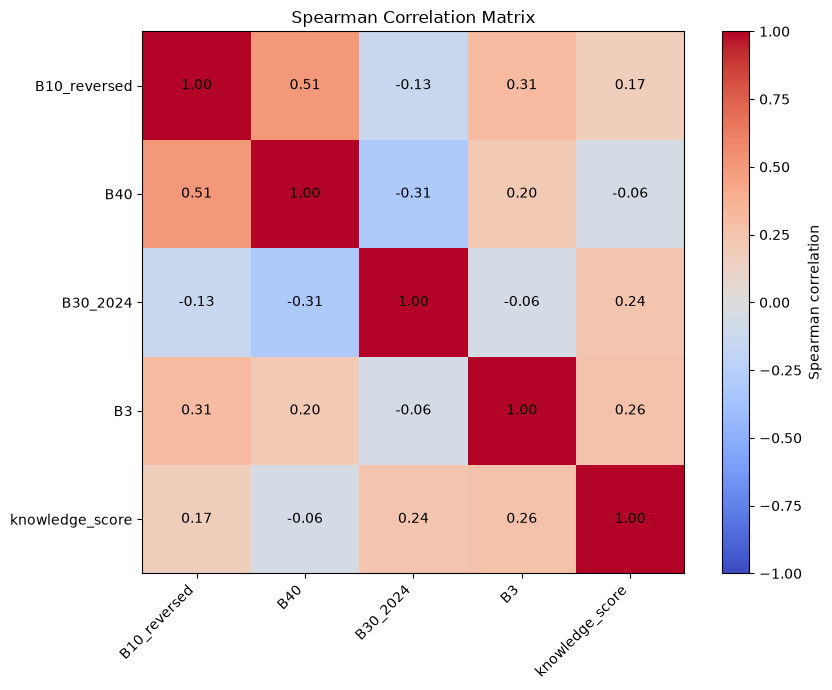

   B10_reversed  B40  B30_2024  B3  knowledge_score
0             2    5         5   0         0.416667
1             1    5         4   3         0.416667
2             2    4         2   1         0.500000
3             1    4         5   2         0.666667
4             1    0         5   1         0.666667

Sample size: 2519

Category mappings: {'B10_reversed': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0}, 'B40': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0, 4: 5.0, 5: 6.0, 6: 7.0}, 'B30_2024': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0, 4: 5.0, 5: 6.0}, 'B3': {0: 1.0, 1: 2.0, 2: 3.0, 3: 4.0}}
Estimating 1 classes...
Finished 1 classes. Converged: True
Estimating 2 classes...
Finished 2 classes. Converged: True
Estimating 3 classes...
Finished 3 classes. Converged: True
Estimating 4 classes...
Finished 4 classes. Converged: True
Estimating 5 classes...
Finished 5 classes. Converged: True
Estimating 6 classes...
Finished 6 classes. Converged: True

MODEL COMPARISON
 Classes  Log likelihood       AIC       BIC  Entropy

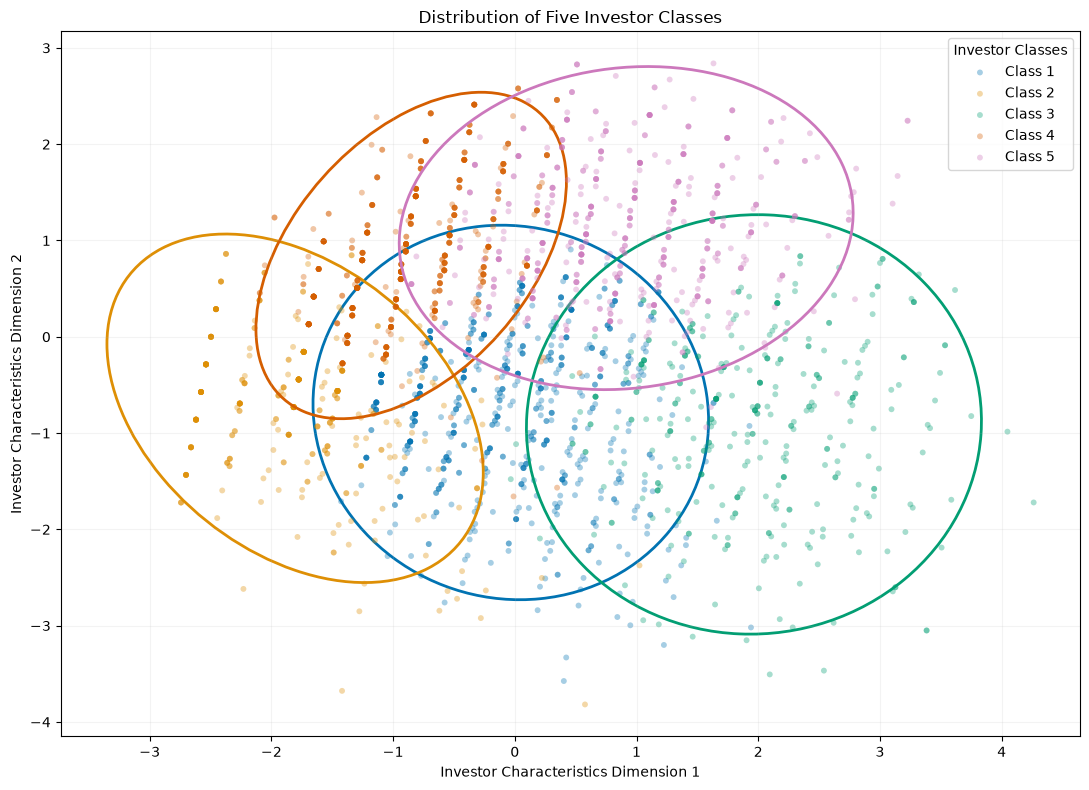

In [1]:
# Data from the previous data preparation and latent class analysis files
%run 02_latent_class_analysis.ipynb

In [2]:
# 3.1 Auxiliary variables
auxiliary_variables = ['S_Gender2', 'S_Age', 'S_Ethnicity', 'S_Education', 'S_Income']

In [3]:
# 3.2 Match auxiliary data to LCA data
aux_data = df.loc[class_data.index, auxiliary_variables].copy()
aux_data["Class"] = class_data["Class"]
print("Auxiliary dataset shape:", aux_data.shape)

Auxiliary dataset shape: (2519, 6)


In [4]:
# 3.3 Auxiliary variables frequencies in each latent class
descriptive_tables = {}
frequency_tables = {}
for var in auxiliary_variables:
    clean = aux_data[["Class", var]]
    frequency = pd.crosstab(
        clean["Class"],
        clean[var]
    )
    percentages = pd.crosstab(
        clean["Class"],
        clean[var],
        normalize="index"
    ) * 100
    frequency_tables[var] = frequency
    descriptive_tables[var] = percentages.round(1)

In [ ]:
# 3.4 Chi-Square and Cramer's V tests
results = []
for var in auxiliary_variables:
    clean = aux_data[["Class", var]]
    table = pd.crosstab(
        clean["Class"],
        clean[var]
    )
    chi2, p, dof, expected = chi2_contingency(table)
    n = table.to_numpy().sum()
    rows, columns = table.shape
    if min(rows - 1, columns - 1) > 0:
        cramers_v = np.sqrt(
            chi2 / (n * min(rows - 1, columns - 1))
        )
    else:
        cramers_v = np.nan
    results.append({
        "Variable": var,
        "N": n,
        "Chi-square": chi2,
        "df": dof,
        "p-value": p,
        "Cramer's V": cramers_v,
    })
print(pd.DataFrame(results))

      Variable     N  Chi-square  df        p-value  Cramer's V
0    S_Gender2  2519  198.577256   4   7.598860e-42    0.280770
1        S_Age  2519  509.746977   8  5.698951e-105    0.318089
2  S_Ethnicity  2519  128.885750   4   6.740271e-27    0.226198
3  S_Education  2519  138.496383   4   5.922808e-29    0.234480
4     S_Income  2519  106.576604   8   1.921318e-19    0.145446


In [8]:
# 3.5 Combine descriptive tables
combined_tables = []
for var in auxiliary_variables:
    percentages = descriptive_tables[var].copy()
    percentages.index = [
        f"Class {class3}"
        for class3 in percentages.index
    ]
    percentages.columns = [
        f"{var}: {category}"
        for category in percentages.columns
    ]
    combined_tables.append(percentages)
combined_table = pd.concat(
    combined_tables,
    axis=1
)
print("COMBINED CLASS DISTRIBUTIONS (%)")
print(combined_table.round(1))

COMBINED CLASS DISTRIBUTIONS (%)
         S_Gender2: 1.0  S_Gender2: 2.0  S_Age: 1.0  S_Age: 2.0  S_Age: 3.0  \
Class 1            44.9            55.1         9.3        36.2        54.5   
Class 2            42.3            57.7         2.8        14.8        82.4   
Class 3            62.3            37.7        24.6        51.7        23.7   
Class 4            68.4            31.6         1.5        13.3        85.3   
Class 5            78.1            21.9         3.8        29.6        66.6   

         S_Ethnicity: 1.0  S_Ethnicity: 2.0  S_Education: 1.0  \
Class 1              74.7              25.3              38.8   
Class 2              86.4              13.6              48.6   
Class 3              59.5              40.5              43.0   
Class 4              87.7              12.3              23.3   
Class 5              81.1              18.9              18.9   

         S_Education: 2.0  S_Income: 1.0  S_Income: 2.0  S_Income: 3.0  
Class 1              61.2   

In [ ]:
# 3.6 Export auxiliary variable analysis results
results = pd.DataFrame(results)
with pd.ExcelWriter("Results/auxiliary_variable_analysis_results.xlsx",
                    engine="openpyxl") as writer:
    results.to_excel(
            writer,
            sheet_name="Chi-square Results",
            index=False
        )
    combined_table.to_excel(
        writer,
        sheet_name="Combined Percentages"
        )